In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

sns.set_theme(style="whitegrid")

In [8]:
df = pd.read_csv("REFIT_House2_Hourly_ML_Input_Candidates.csv")

df['Hour'] = pd.to_datetime(df['Hour'])

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully
Shape: (10871, 28)


,Hour,Appliance1_Energy_kWh,Appliance2_Energy_kWh,Appliance3_Energy_kWh,Appliance4_Energy_kWh,Appliance5_Energy_kWh,Appliance6_Energy_kWh,Appliance7_Energy_kWh,Appliance8_Energy_kWh,Appliance9_Energy_kWh,Appliance1_mean,Appliance1_max,Appliance2_mean,Appliance2_max,Appliance3_mean,Appliance3_max,Appliance4_mean,Appliance4_max,Appliance5_mean,Appliance5_max,Appliance6_mean,Appliance6_max,Appliance7_mean,Appliance7_max,Appliance8_mean,Appliance8_max,Appliance9_mean,Appliance9_max
0,2013-09-17 23:00:00,0.028113,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.081871,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2013-09-18 00:00:00,0.034448,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.347245,97.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2013-09-18 01:00:00,0.034120,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.171667,94.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2013-09-18 02:00:00,0.004077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.184122,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2013-09-18 03:00:00,0.031556,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.575251,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10871 entries, 0 to 10870
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Hour                   10871 non-null  datetime64[us]
 1   Appliance1_Energy_kWh  10870 non-null  float64       
 2   Appliance2_Energy_kWh  10859 non-null  float64       
 3   Appliance3_Energy_kWh  10864 non-null  float64       
 4   Appliance4_Energy_kWh  10870 non-null  float64       
 5   Appliance5_Energy_kWh  10871 non-null  float64       
 6   Appliance6_Energy_kWh  10861 non-null  float64       
 7   Appliance7_Energy_kWh  10819 non-null  float64       
 8   Appliance8_Energy_kWh  10857 non-null  float64       
 9   Appliance9_Energy_kWh  10871 non-null  float64       
 10  Appliance1_mean        10870 non-null  float64       
 11  Appliance1_max         10870 non-null  float64       
 12  Appliance2_mean        10867 non-null  float64       
 13  Appliance2_m

In [10]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns containing missing values:")
display(missing)

print("Total missing cells:", df.isnull().sum().sum())

Columns containing missing values:


Appliance7_Energy_kWh    52
Appliance7_max           26
Appliance7_mean          26
Appliance8_Energy_kWh    14
Appliance8_mean          13
Appliance8_max           13
Appliance2_Energy_kWh    12
Appliance6_Energy_kWh    10
Appliance3_Energy_kWh     7
Appliance3_max            4
Appliance3_mean           4
Appliance2_max            4
Appliance2_mean           4
Appliance6_mean           2
Appliance6_max            2
Appliance4_Energy_kWh     1
Appliance1_Energy_kWh     1
Appliance1_mean           1
Appliance1_max            1
Appliance4_mean           1
Appliance4_max            1
dtype: int64

Total missing cells: 199


In [11]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:", df['Hour'].duplicated().sum())

print("Chronological order:", df['Hour'].is_monotonic_increasing)

time_gaps = df['Hour'].diff().value_counts()

print("\nTime interval distribution:")
display(time_gaps.head(15))

Duplicate rows: 0
Duplicate timestamps: 0
Chronological order: True

Time interval distribution:


Hour
0 days 01:00:00     10685
0 days 02:00:00       112
0 days 03:00:00        33
0 days 04:00:00         9
0 days 05:00:00         5
0 days 06:00:00         3
0 days 07:00:00         2
0 days 22:00:00         2
62 days 01:00:00        1
56 days 02:00:00        1
1 days 01:00:00         1
1 days 18:00:00         1
1 days 19:00:00         1
1 days 00:00:00         1
1 days 22:00:00         1
Name: count, dtype: int64

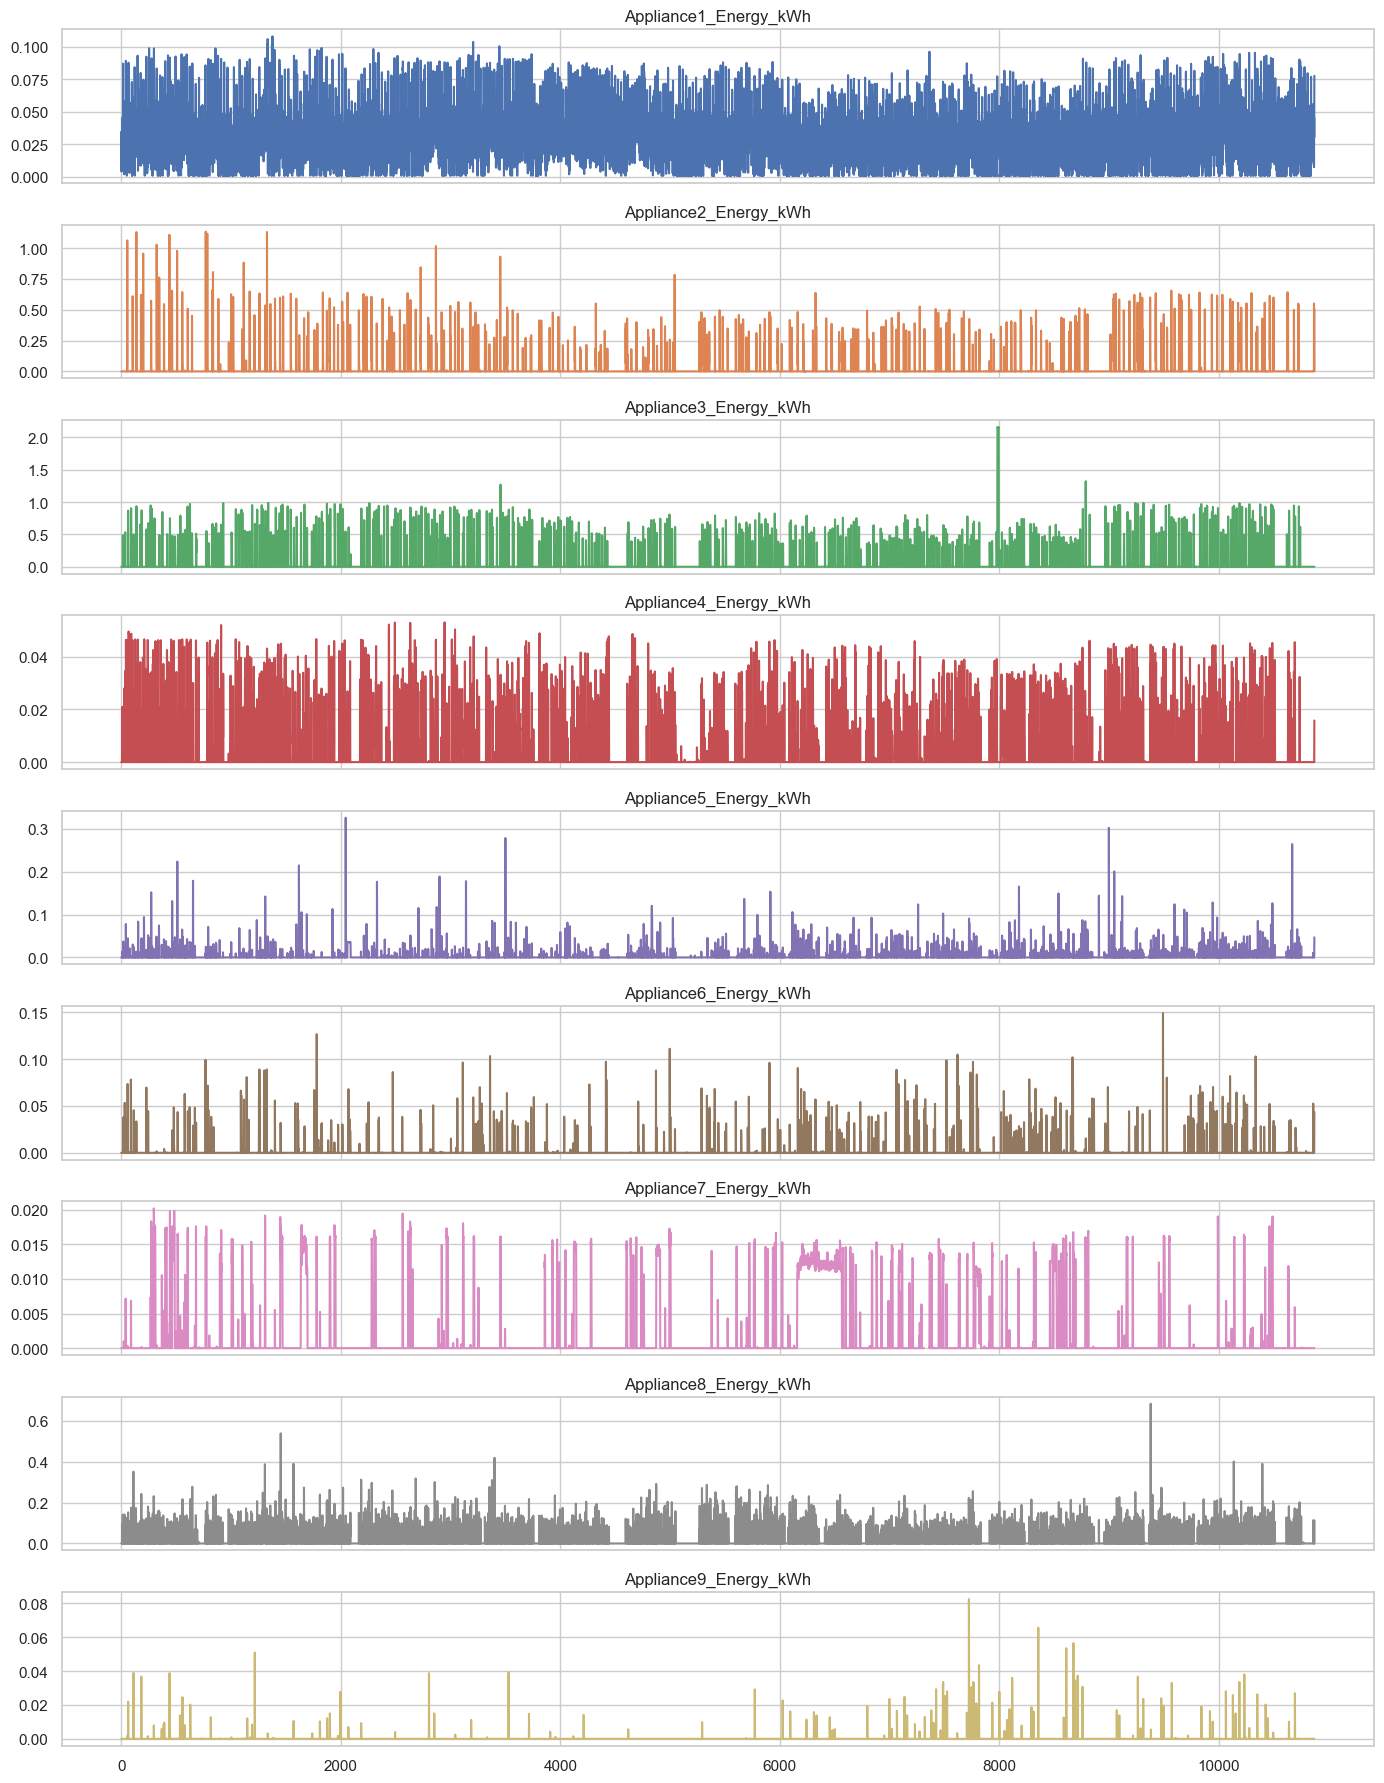

In [12]:
energy_columns = [
    f'Appliance{i}_Energy_kWh'
    for i in range(1, 10)
]

df[energy_columns].plot(
    subplots=True,
    figsize=(14, 18),
    legend=False,
    title=energy_columns
)

plt.tight_layout()
plt.show()

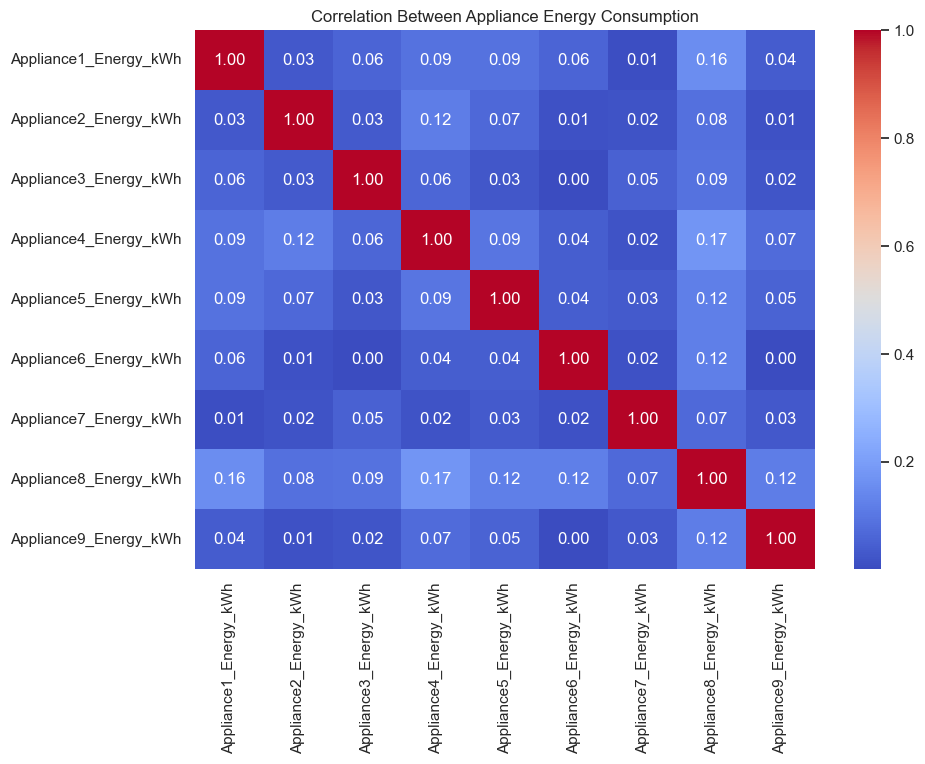

In [13]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[energy_columns].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Appliance Energy Consumption")
plt.show()

phase 2: data splitting(for training validation and testing) and baseline(make a simple baseline prediction)

Import libraries and load dataset

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("REFIT_House2_Hourly_ML_Input_Candidates.csv")

# Convert Hour into datetime
df['Hour'] = pd.to_datetime(df['Hour'])

# Sort chronologically
df = df.sort_values('Hour').reset_index(drop=True)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (10871, 28)


,Hour,Appliance1_Energy_kWh,Appliance2_Energy_kWh,Appliance3_Energy_kWh,Appliance4_Energy_kWh,Appliance5_Energy_kWh,Appliance6_Energy_kWh,Appliance7_Energy_kWh,Appliance8_Energy_kWh,Appliance9_Energy_kWh,Appliance1_mean,Appliance1_max,Appliance2_mean,Appliance2_max,Appliance3_mean,Appliance3_max,Appliance4_mean,Appliance4_max,Appliance5_mean,Appliance5_max,Appliance6_mean,Appliance6_max,Appliance7_mean,Appliance7_max,Appliance8_mean,Appliance8_max,Appliance9_mean,Appliance9_max
0,2013-09-17 23:00:00,0.028113,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.081871,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2013-09-18 00:00:00,0.034448,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.347245,97.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2013-09-18 01:00:00,0.034120,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.171667,94.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2013-09-18 02:00:00,0.004077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.184122,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2013-09-18 03:00:00,0.031556,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.575251,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Define appliance energy columns

In [18]:
energy_columns = [
    f'Appliance{i}_Energy_kWh'
    for i in range(1, 10)
]

print("Appliance energy columns:")
for col in energy_columns:
    print(col)

Appliance energy columns:
Appliance1_Energy_kWh
Appliance2_Energy_kWh
Appliance3_Energy_kWh
Appliance4_Energy_kWh
Appliance5_Energy_kWh
Appliance6_Energy_kWh
Appliance7_Energy_kWh
Appliance8_Energy_kWh
Appliance9_Energy_kWh


Create the target variable
Our target is the sum of the nine appliance energy readings for each hour

In [19]:
df['Total_Energy_kWh'] = df[energy_columns].sum(
    axis=1,
    min_count=9
)

print("Target variable created successfully")

display(
    df[['Hour', 'Total_Energy_kWh']].head(10)
)

print(
    "Missing target values:",
    df['Total_Energy_kWh'].isnull().sum()
)

Target variable created successfully


,Hour,Total_Energy_kWh
0,2013-09-17 23:00:00,0.028113
1,2013-09-18 00:00:00,0.034448
2,2013-09-18 01:00:00,0.034120
3,2013-09-18 02:00:00,0.004077
4,2013-09-18 03:00:00,0.031556
5,2013-09-18 04:00:00,0.034870
6,2013-09-18 05:00:00,0.005994
7,2013-09-18 06:00:00,0.030566
8,2013-09-18 07:00:00,0.148186
9,2013-09-18 08:00:00,0.058033


Missing target values: 91


Create a continuous hourly timeline

In [20]:
df = df.set_index('Hour')

# Generate continuous hourly index
hourly_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq='h'
)

# Reindex the dataset
df = df.reindex(hourly_index)

df.index.name = 'Hour'

print("Continuous hourly dataset created")
print("New dataset shape:", df.shape)

print(
    "Missing timestamps/rows introduced:",
    df['Total_Energy_kWh'].isnull().sum()
)

Continuous hourly dataset created
New dataset shape: (14817, 28)
Missing timestamps/rows introduced: 4037


Generate lag features

In [21]:
# Previous-hour appliance energy consumption
for col in energy_columns:
    df[f'{col}_lag1'] = df[col].shift(1)

# Previous-hour total energy consumption
df['Previous_Total_Energy_kWh'] = (
    df['Total_Energy_kWh'].shift(1)
)

print("Lag features created successfully")

display(df.head(10))

Lag features created successfully


,Appliance1_Energy_kWh,Appliance2_Energy_kWh,Appliance3_Energy_kWh,Appliance4_Energy_kWh,Appliance5_Energy_kWh,Appliance6_Energy_kWh,Appliance7_Energy_kWh,Appliance8_Energy_kWh,Appliance9_Energy_kWh,Appliance1_mean,Appliance1_max,Appliance2_mean,Appliance2_max,Appliance3_mean,Appliance3_max,Appliance4_mean,Appliance4_max,Appliance5_mean,Appliance5_max,Appliance6_mean,Appliance6_max,Appliance7_mean,Appliance7_max,Appliance8_mean,Appliance8_max,Appliance9_mean,Appliance9_max,Total_Energy_kWh,Appliance1_Energy_kWh_lag1,Appliance2_Energy_kWh_lag1,Appliance3_Energy_kWh_lag1,Appliance4_Energy_kWh_lag1,Appliance5_Energy_kWh_lag1,Appliance6_Energy_kWh_lag1,Appliance7_Energy_kWh_lag1,Appliance8_Energy_kWh_lag1,Appliance9_Energy_kWh_lag1,Previous_Total_Energy_kWh
Hour,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2013-09-17 23:00:00,0.028113,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,33.081871,88.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.028113,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-09-18 00:00:00,0.034448,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,34.347245,97.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.034448,0.028113,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.028113
2013-09-18 01:00:00,0.034120,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,34.171667,94.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.034120,0.034448,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.034448
2013-09-18 02:00:00,0.004077,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,4.184122,127.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.004077,0.034120,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.034120
2013-09-18 03:00:00,0.031556,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,31.575251,88.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.031556,0.004077,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.004077
2013-09-18 04:00:00,0.034870,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,35.535117,97.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.034870,0.031556,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.031556
2013-09-18 05:00:00,0.005994,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,5.973154,95.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.005994,0.034870,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.034870
2013-09-18 06:00:00,0.030566,0.0,0.0,0.000000,0.00000,0.0,0.0,0.000000,0.0,31.005000,88.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.030566,0.005994,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.005994
2013-09-18 07:00:00,0.045183,0.0,0.0,0.007640,0.00000,0.0,0.0,0.095363,0.0,44.905724,96.0,0.0,0.0,0.0,0.0,7.478114,61.0,0.000000,0.0,0.0,0.0,0.0,0.0,98.520202,2687.0,0.0,0.0,0.148186,0.030566,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.030566


Generate time-related features

In [22]:
# Extract time features
df['Hour_of_Day'] = df.index.hour

df['Day_of_Week'] = df.index.dayofweek

df['Month'] = df.index.month

# Cyclical encoding of hour
df['Hour_sin'] = np.sin(
    2 * np.pi * df['Hour_of_Day'] / 24
)

df['Hour_cos'] = np.cos(
    2 * np.pi * df['Hour_of_Day'] / 24
)

print("Time-related features created successfully")

display(
    df[
        [
            'Hour_of_Day',
            'Day_of_Week',
            'Month',
            'Hour_sin',
            'Hour_cos'
        ]
    ].head()
)

Time-related features created successfully


,Hour_of_Day,Day_of_Week,Month,Hour_sin,Hour_cos
Hour,,,,,
2013-09-17 23:00:00,23,1,9,-0.258819,0.965926
2013-09-18 00:00:00,0,2,9,0.000000,1.000000
2013-09-18 01:00:00,1,2,9,0.258819,0.965926
2013-09-18 02:00:00,2,2,9,0.500000,0.866025
2013-09-18 03:00:00,3,2,9,0.707107,0.707107


Define input features (X) and target (y)

In [23]:
lag_columns = [
    f'{col}_lag1'
    for col in energy_columns
]

feature_columns = (
    lag_columns +
    [
        'Previous_Total_Energy_kWh',
        'Hour_sin',
        'Hour_cos',
        'Day_of_Week',
        'Month'
    ]
)

# Input features
X = df[feature_columns].copy()

# Prediction target
y = df['Total_Energy_kWh'].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(feature_columns)

display(X.head())
display(y.head())

Input features shape: (14817, 14)
Target shape: (14817,)

Input feature names:
['Appliance1_Energy_kWh_lag1', 'Appliance2_Energy_kWh_lag1', 'Appliance3_Energy_kWh_lag1', 'Appliance4_Energy_kWh_lag1', 'Appliance5_Energy_kWh_lag1', 'Appliance6_Energy_kWh_lag1', 'Appliance7_Energy_kWh_lag1', 'Appliance8_Energy_kWh_lag1', 'Appliance9_Energy_kWh_lag1', 'Previous_Total_Energy_kWh', 'Hour_sin', 'Hour_cos', 'Day_of_Week', 'Month']


,Appliance1_Energy_kWh_lag1,Appliance2_Energy_kWh_lag1,Appliance3_Energy_kWh_lag1,Appliance4_Energy_kWh_lag1,Appliance5_Energy_kWh_lag1,Appliance6_Energy_kWh_lag1,Appliance7_Energy_kWh_lag1,Appliance8_Energy_kWh_lag1,Appliance9_Energy_kWh_lag1,Previous_Total_Energy_kWh,Hour_sin,Hour_cos,Day_of_Week,Month
Hour,,,,,,,,,,,,,,
2013-09-17 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.258819,0.965926,1,9
2013-09-18 00:00:00,0.028113,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.028113,0.000000,1.000000,2,9
2013-09-18 01:00:00,0.034448,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.034448,0.258819,0.965926,2,9
2013-09-18 02:00:00,0.034120,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.034120,0.500000,0.866025,2,9
2013-09-18 03:00:00,0.004077,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.004077,0.707107,0.707107,2,9


Hour
2013-09-17 23:00:00    0.028113
2013-09-18 00:00:00    0.034448
2013-09-18 01:00:00    0.034120
2013-09-18 02:00:00    0.004077
2013-09-18 03:00:00    0.031556
Freq: h, Name: Total_Energy_kWh, dtype: float64

Remove observations with missing target values

In [24]:
# Keep only observations with valid target values
valid_target = y.notna()

X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("Observations after removing missing targets:", len(X))

print(
    "Missing input feature values:",
    X.isnull().sum().sum()
)

print(
    "Missing target values:",
    y.isnull().sum()
)

Observations after removing missing targets: 10780
Missing input feature values: 1869
Missing target values: 0


Split data into training, validation and testing

In [26]:
# Calculate split indices
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Training data
X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

# Validation data
X_val = X.iloc[train_end:val_end].copy()
y_val = y.iloc[train_end:val_end].copy()

# Testing data
X_test = X.iloc[val_end:].copy()
y_test = y.iloc[val_end:].copy()

print("TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDATION DATA")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

TRAINING DATA
X_train: (7545, 14)
y_train: (7545,)

VALIDATION DATA
X_val: (1618, 14)
y_val: (1618,)

TESTING DATA
X_test: (1617, 14)
y_test: (1617,)


Verify chronological splitting

In [27]:
print("TRAINING PERIOD")
print(X_train.index.min(), "to", X_train.index.max())

print("\nVALIDATION PERIOD")
print(X_val.index.min(), "to", X_val.index.max())

print("\nTESTING PERIOD")
print(X_test.index.min(), "to", X_test.index.max())

# Verify chronological order
assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

print("\nChronological splitting verified successfully!")

TRAINING PERIOD
2013-09-17 23:00:00 to 2014-12-20 14:00:00

VALIDATION PERIOD
2014-12-20 15:00:00 to 2015-03-04 07:00:00

TESTING PERIOD
2015-03-04 08:00:00 to 2015-05-28 07:00:00

Chronological splitting verified successfully!


Establish baseline models

In [28]:
# BASELINE 1: Training mean prediction

mean_prediction = np.full(
    len(y_val),
    y_train.mean()
)

# BASELINE 2: Previous-hour consumption prediction

persistence_prediction = X_val[
    'Previous_Total_Energy_kWh'
]

# Identify observations with valid previous-hour readings
valid_persistence = persistence_prediction.notna()

print("Mean baseline predictions:", len(mean_prediction))

print(
    "Valid persistence predictions:",
    valid_persistence.sum()
)

Mean baseline predictions: 1618
Valid persistence predictions: 1550


Evaluate baseline models

In [36]:
# Function to calculate evaluation metrics

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    return mae, mse, rmse


# Evaluate Mean Baseline

mean_mae, mean_mse, mean_rmse = evaluate_model(
    y_val,
    mean_prediction
)


# Evaluate Persistence Baseline

persistence_mae, persistence_mse, persistence_rmse = evaluate_model(
    y_val[valid_persistence],
    persistence_prediction[valid_persistence]
)


# Create comparison table

baseline_results = pd.DataFrame({
    'Model': [
        'Mean Baseline',
        'Persistence Baseline'
    ],

    'MAE': [
        mean_mae,
        persistence_mae
    ],

    'MSE': [
        mean_mse,
        persistence_mse
    ],

    'RMSE': [
        mean_rmse,
        persistence_rmse
    ]
})

print("BASELINE MODEL PERFORMANCE")

display(baseline_results.round(6))

BASELINE MODEL PERFORMANCE


,Model,MAE,MSE,RMSE
0,Mean Baseline,0.127576,0.035124,0.187414
1,Persistence Baseline,0.108764,0.039069,0.197658


Visualize baseline performance

<Figure size 1000x500 with 0 Axes>

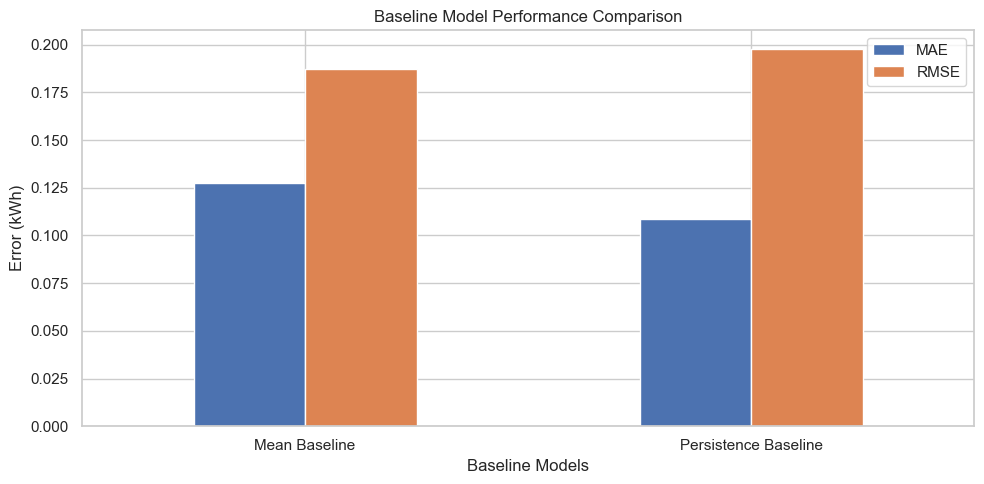

In [30]:
plt.figure(figsize=(10, 5))

baseline_results.set_index('Model')[
    ['MAE', 'RMSE']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Baseline Model Performance Comparison")

plt.ylabel("Error (kWh)")

plt.xlabel("Baseline Models")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

Visualize actual vs predicted consumption

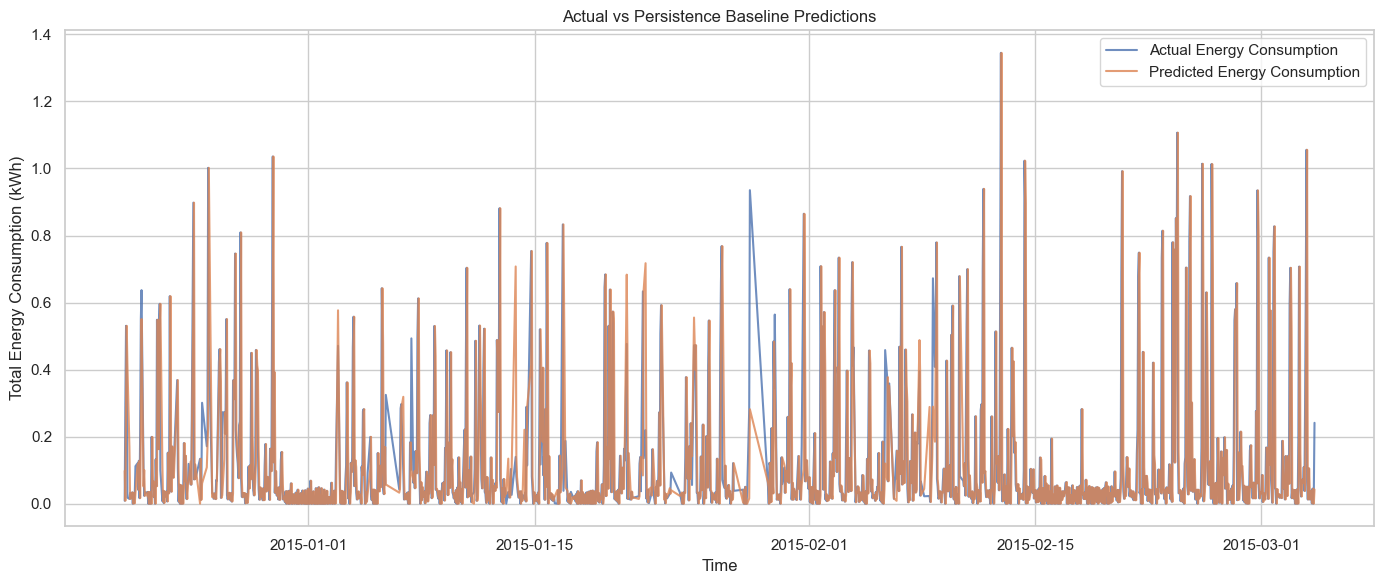

In [31]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_val[valid_persistence].index,
    y_val[valid_persistence],
    label='Actual Energy Consumption',
    alpha=0.8
)

plt.plot(
    persistence_prediction[valid_persistence].index,
    persistence_prediction[valid_persistence],
    label='Predicted Energy Consumption',
    alpha=0.8
)

plt.title("Actual vs Persistence Baseline Predictions")

plt.xlabel("Time")

plt.ylabel("Total Energy Consumption (kWh)")

plt.legend()

plt.tight_layout()

plt.show()

Final Phase 2 summary

In [32]:
print("=" * 50)
print("PHASE 2 - COMPLETION SUMMARY")
print("=" * 50)

print("Total usable observations:", len(X))

print("\nTraining observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nNumber of input features:", X.shape[1])

print("\nBaseline Performance:")
display(baseline_results.round(6))

print("\nPhase 2 completed successfully!")

PHASE 2 - COMPLETION SUMMARY
Total usable observations: 10780

Training observations: 7545
Validation observations: 1618
Testing observations: 1617

Number of input features: 14

Baseline Performance:


,Model,MAE,MSE,RMSE
0,Mean Baseline,0.127576,0.035124,0.187414
1,Persistence Baseline,0.108764,0.039069,0.197658



Phase 2 completed successfully!


Phase 3 – Machine Learning Model Implementation

Import ML libraries

In [37]:
# Machine Learning algorithms

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Preprocessing tools

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Pipeline

from sklearn.pipeline import Pipeline

# Evaluation metrics

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Machine Learning libraries imported successfully")

Machine Learning libraries imported successfully


Verify training and validation datasets

In [38]:
print("TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDATION DATA")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nMissing values in training features:")
print(X_train.isnull().sum())

print("\nTotal missing training feature values:",
      X_train.isnull().sum().sum())

TRAINING DATA
X_train: (7545, 14)
y_train: (7545,)

VALIDATION DATA
X_val: (1618, 14)
y_val: (1618,)

TESTING DATA
X_test: (1617, 14)
y_test: (1617,)

Missing values in training features:
Appliance1_Energy_kWh_lag1    109
Appliance2_Energy_kWh_lag1    114
Appliance3_Energy_kWh_lag1    109
Appliance4_Energy_kWh_lag1    109
Appliance5_Energy_kWh_lag1    109
Appliance6_Energy_kWh_lag1    110
Appliance7_Energy_kWh_lag1    111
Appliance8_Energy_kWh_lag1    109
Appliance9_Energy_kWh_lag1    109
Previous_Total_Energy_kWh     117
Hour_sin                        0
Hour_cos                        0
Day_of_Week                     0
Month                           0
dtype: int64

Total missing training feature values: 1106


Define preprocessing pipelines

In [39]:
# Preprocessing for Linear Regression

linear_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Preprocessing for Tree-based models

tree_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

print("Preprocessing pipelines defined successfully")

Preprocessing pipelines defined successfully


Implement Linear Regression

In [40]:
# Create Linear Regression pipeline

linear_model = Pipeline([
    ('preprocessing', linear_preprocessing),
    ('regressor', LinearRegression())
])


# Train the model

linear_model.fit(X_train, y_train)


# Generate validation predictions

linear_predictions = linear_model.predict(X_val)


print("Linear Regression trained successfully")

print("\nFirst 10 predictions:")
print(linear_predictions[:10])

Linear Regression trained successfully

First 10 predictions:
[0.17163463 0.11700011 0.23406962 0.33549914 0.26544242 0.07265189
 0.19891868 0.05224672 0.03983099 0.03249841]


Implement Random Forest Regression

In [41]:
# Create Random Forest pipeline

random_forest_model = Pipeline([
    ('preprocessing', tree_preprocessing),

    ('regressor', RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])


# Train the model

random_forest_model.fit(X_train, y_train)


# Generate validation predictions

rf_predictions = random_forest_model.predict(X_val)


print("Random Forest Regression trained successfully")

print("\nFirst 10 predictions:")
print(rf_predictions[:10])

Random Forest Regression trained successfully

First 10 predictions:
[0.34668397 0.12213413 0.41455182 0.42665707 0.54361232 0.15532423
 0.12885478 0.04103325 0.01806965 0.0327492 ]


Implement Gradient Boosting Regression

In [42]:
# Create Gradient Boosting pipeline

gradient_boosting_model = Pipeline([
    ('preprocessing', tree_preprocessing),

    ('regressor', GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        loss='squared_error',
        random_state=42
    ))
])


# Train the model

gradient_boosting_model.fit(X_train, y_train)


# Generate validation predictions

gb_predictions = gradient_boosting_model.predict(X_val)


print("Gradient Boosting Regression trained successfully")

print("\nFirst 10 predictions:")
print(gb_predictions[:10])

Gradient Boosting Regression trained successfully

First 10 predictions:
[0.15373343 0.12911221 0.47307488 0.42855473 0.39034582 0.07430278
 0.13556887 0.03650917 0.0342516  0.0342516 ]


Create a common evaluation function

In [43]:
def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    return {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse
    }


print("Evaluation function created successfully")

Evaluation function created successfully


Evaluate all three models

In [44]:
# Evaluate Linear Regression

linear_results = evaluate_model(
    y_val,
    linear_predictions
)


# Evaluate Random Forest

rf_results = evaluate_model(
    y_val,
    rf_predictions
)


# Evaluate Gradient Boosting

gb_results = evaluate_model(
    y_val,
    gb_predictions
)


# Create comparison table

model_results = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        **linear_results
    },
    {
        'Model': 'Random Forest',
        **rf_results
    },
    {
        'Model': 'Gradient Boosting',
        **gb_results
    }
])


print("MODEL PERFORMANCE ON VALIDATION DATA")

display(model_results.round(6))

MODEL PERFORMANCE ON VALIDATION DATA


,Model,MAE,MSE,RMSE
0,Linear Regression,0.107749,0.027297,0.165217
1,Random Forest,0.096271,0.022956,0.151513
2,Gradient Boosting,0.087578,0.021110,0.145294


Compare models visually

<Figure size 1100x500 with 0 Axes>

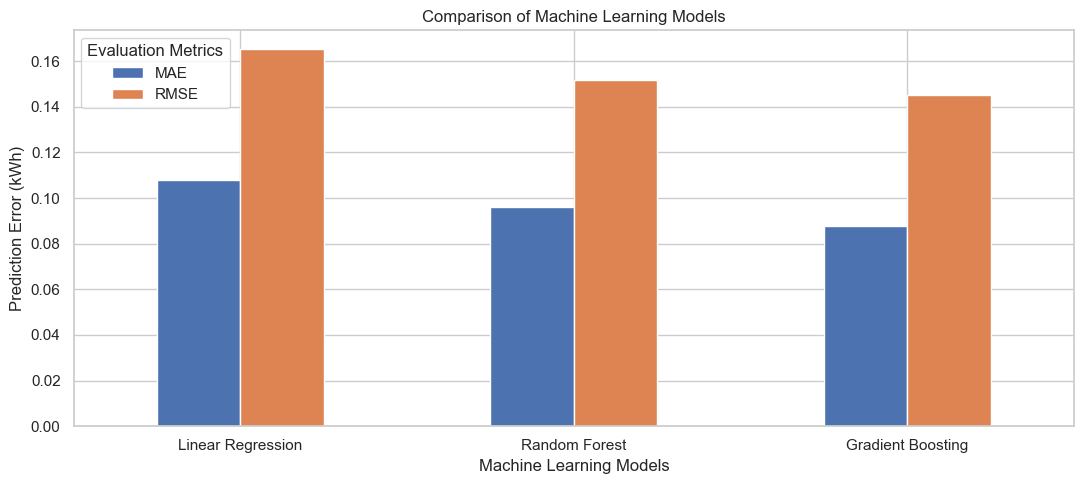

In [45]:
plt.figure(figsize=(11, 5))

model_results.set_index('Model')[
    ['MAE', 'RMSE']
].plot(
    kind='bar',
    figsize=(11, 5)
)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("Machine Learning Models")

plt.ylabel("Prediction Error (kWh)")

plt.xticks(rotation=0)

plt.legend(title="Evaluation Metrics")

plt.tight_layout()

plt.show()

Identify the best initial model

In [48]:
best_model_name = model_results.loc[
    model_results['RMSE'].idxmin(),
    'Model'
]

best_rmse = model_results['RMSE'].min()

print("BEST INITIAL MODEL")
print("------------------------------")

print("Model:", best_model_name)

print("Validation RMSE:", best_rmse)

print("------------------------------")

BEST INITIAL MODEL
------------------------------
Model: Gradient Boosting
Validation RMSE: 0.1452935179095299
------------------------------


Baseline vs ML model comparison

In [49]:
# Select validation observations with previous-hour readings

common_mask = X_val[
    'Previous_Total_Energy_kWh'
].notna()

actual_common = y_val.loc[common_mask]


# Mean baseline

mean_common = np.full(
    len(actual_common),
    y_train.mean()
)


# Persistence baseline

persistence_common = X_val.loc[
    common_mask,
    'Previous_Total_Energy_kWh'
]


# ML predictions on the same observations

linear_common = linear_predictions[
    common_mask.to_numpy()
]

rf_common = rf_predictions[
    common_mask.to_numpy()
]

gb_common = gb_predictions[
    common_mask.to_numpy()
]


# Evaluate all approaches

comparison_results = pd.DataFrame([
    {
        'Model': 'Mean Baseline',
        **evaluate_model(actual_common, mean_common)
    },
    {
        'Model': 'Persistence Baseline',
        **evaluate_model(actual_common, persistence_common)
    },
    {
        'Model': 'Linear Regression',
        **evaluate_model(actual_common, linear_common)
    },
    {
        'Model': 'Random Forest',
        **evaluate_model(actual_common, rf_common)
    },
    {
        'Model': 'Gradient Boosting',
        **evaluate_model(actual_common, gb_common)
    }
])

print("BASELINE VS MACHINE LEARNING COMPARISON")

display(comparison_results.round(6))

BASELINE VS MACHINE LEARNING COMPARISON


,Model,MAE,MSE,RMSE
0,Mean Baseline,0.127747,0.035163,0.187518
1,Persistence Baseline,0.108764,0.039069,0.197658
2,Linear Regression,0.107745,0.027043,0.164449
3,Random Forest,0.095994,0.022834,0.151109
4,Gradient Boosting,0.086889,0.020626,0.143617


Visualize the complete comparison

<Figure size 1200x600 with 0 Axes>

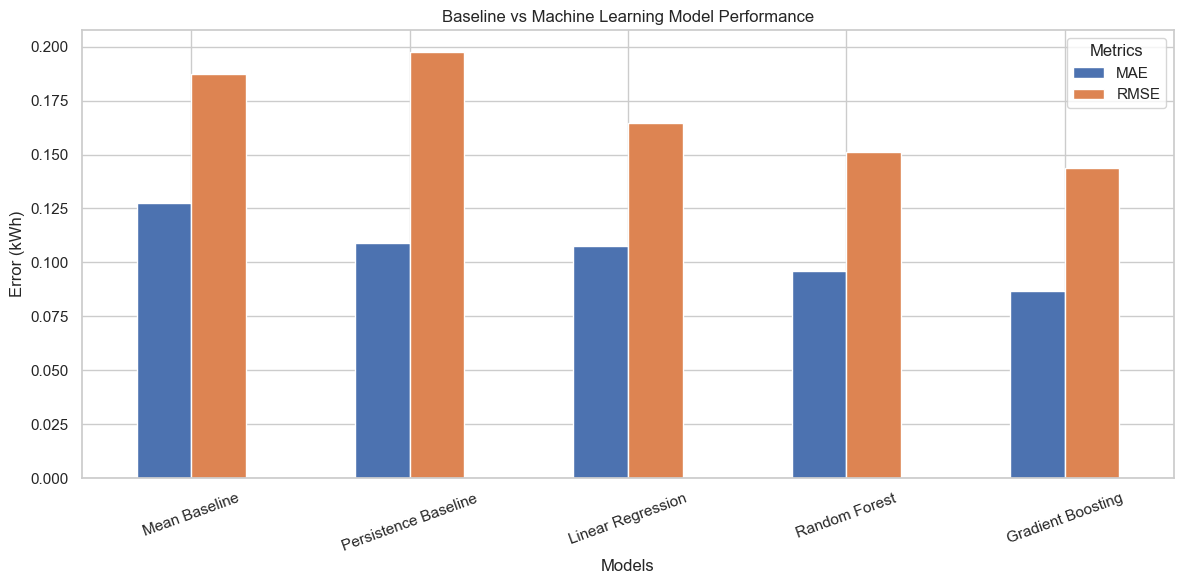

In [50]:
plt.figure(figsize=(12, 6))

comparison_results.set_index('Model')[
    ['MAE', 'RMSE']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Baseline vs Machine Learning Model Performance")

plt.xlabel("Models")

plt.ylabel("Error (kWh)")

plt.xticks(rotation=20)

plt.legend(title="Metrics")

plt.tight_layout()

plt.show()

Save validation predictions

In [46]:
validation_predictions = pd.DataFrame(
    {
        'Actual_Energy_kWh': y_val,
        'Linear_Regression': linear_predictions,
        'Random_Forest': rf_predictions,
        'Gradient_Boosting': gb_predictions
    },
    index=y_val.index
)

display(validation_predictions.head(15))

# Save predictions
validation_predictions.to_csv(
    'Phase3_Validation_Predictions.csv'
)

print("Validation predictions saved successfully")

,Actual_Energy_kWh,Linear_Regression,Random_Forest,Gradient_Boosting
Hour,,,,
2014-12-20 15:00:00,0.009470,0.171635,0.346684,0.153733
2014-12-20 16:00:00,0.301425,0.117000,0.122134,0.129112
2014-12-20 17:00:00,0.530898,0.234070,0.414552,0.473075
2014-12-20 18:00:00,0.418514,0.335499,0.426657,0.428555
2014-12-20 19:00:00,0.018969,0.265442,0.543612,0.390346
2014-12-20 21:00:00,0.169821,0.072652,0.155324,0.074303
2014-12-20 22:00:00,0.014943,0.198919,0.128855,0.135569
2014-12-20 23:00:00,0.032853,0.052247,0.041033,0.036509
2014-12-21 00:00:00,0.016305,0.039831,0.018070,0.034252


Validation predictions saved successfully


print("=" * 55)
print("PHASE 3 - MACHINE LEARNING IMPLEMENTATION")
print("=" * 55)

print("\nModels implemented:")
print("1. Linear Regression")
print("2. Random Forest Regression")
print("3. Gradient Boosting Regression")

print("\nTraining observations:", len(X_train))
print("Validation observations:", len(X_val))

print("\nNumber of input features:", X_train.shape[1])

print("\nModel Performance:")
display(model_results.round(6))

print("\nBaseline Comparison:")
display(comparison_results.round(6))

print("\nBest initial model:", best_model_name)

print("\nPHASE 3 COMPLETED SUCCESSFULLY")

In [51]:
print("=" * 55)
print("PHASE 3 - MACHINE LEARNING IMPLEMENTATION")
print("=" * 55)

print("\nModels implemented:")
print("1. Linear Regression")
print("2. Random Forest Regression")
print("3. Gradient Boosting Regression")

print("\nTraining observations:", len(X_train))
print("Validation observations:", len(X_val))

print("\nNumber of input features:", X_train.shape[1])

print("\nModel Performance:")
display(model_results.round(6))

print("\nBaseline Comparison:")
display(comparison_results.round(6))

print("\nBest initial model:", best_model_name)

print("\nPHASE 3 COMPLETED SUCCESSFULLY")

PHASE 3 - MACHINE LEARNING IMPLEMENTATION

Models implemented:
1. Linear Regression
2. Random Forest Regression
3. Gradient Boosting Regression

Training observations: 7545
Validation observations: 1618

Number of input features: 14

Model Performance:


,Model,MAE,MSE,RMSE
0,Linear Regression,0.107749,0.027297,0.165217
1,Random Forest,0.096271,0.022956,0.151513
2,Gradient Boosting,0.087578,0.021110,0.145294



Baseline Comparison:


,Model,MAE,MSE,RMSE
0,Mean Baseline,0.127747,0.035163,0.187518
1,Persistence Baseline,0.108764,0.039069,0.197658
2,Linear Regression,0.107745,0.027043,0.164449
3,Random Forest,0.095994,0.022834,0.151109
4,Gradient Boosting,0.086889,0.020626,0.143617



Best initial model: Gradient Boosting

PHASE 3 COMPLETED SUCCESSFULLY


Phase 4 — Model evaluation and hyperparameter tuning

Hyperparameter tuning

In [52]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

# Time-series cross-validation:
# Each validation fold comes AFTER its training fold.
tscv = TimeSeriesSplit(n_splits=4)

# --------------------------------------------------
# 1. RANDOM FOREST TUNING
# --------------------------------------------------

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_parameters = {
    'regressor__n_estimators': [100, 200, 300, 400],
    'regressor__max_depth': [None, 5, 10, 15, 20],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4],
    'regressor__max_features': ['sqrt', 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Tuning Random Forest...")
rf_search.fit(X_train, y_train)

best_rf_model = rf_search.best_estimator_

print("\nBest Random Forest Parameters:")
print(rf_search.best_params_)

print("Best Random Forest CV RMSE:",
      -rf_search.best_score_)


# --------------------------------------------------
# 2. GRADIENT BOOSTING TUNING
# --------------------------------------------------

gb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', GradientBoostingRegressor(
        random_state=42
    ))
])

gb_parameters = {
    'regressor__n_estimators': [100, 150, 200, 300, 400],
    'regressor__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'regressor__max_depth': [1, 2, 3, 4, 5],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4],
    'regressor__subsample': [0.7, 0.8, 0.9, 1.0],
    'regressor__max_features': [None, 'sqrt', 0.7]
}

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_parameters,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTuning Gradient Boosting...")
gb_search.fit(X_train, y_train)

best_gb_model = gb_search.best_estimator_

print("\nBest Gradient Boosting Parameters:")
print(gb_search.best_params_)

print("Best Gradient Boosting CV RMSE:",
      -gb_search.best_score_)

Tuning Random Forest...
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best Random Forest Parameters:
{'regressor__n_estimators': 400, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 1.0, 'regressor__max_depth': 5}
Best Random Forest CV RMSE: 0.14218467084260164

Tuning Gradient Boosting...
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best Gradient Boosting Parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 150, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': None, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.03}
Best Gradient Boosting CV RMSE: 0.14356513640084104


Compare original and tuned models

PHASE 4: ORIGINAL VS TUNED MODEL PERFORMANCE


,Model,MAE,MSE,RMSE
0,Tuned Random Forest,0.085524,0.020578,0.143451
1,Original Gradient Boosting,0.086889,0.020626,0.143617
2,Tuned Gradient Boosting,0.086254,0.021075,0.145173
3,Original Random Forest,0.095994,0.022834,0.151109
4,Linear Regression,0.107745,0.027043,0.164449
5,Mean Baseline,0.127747,0.035163,0.187518
6,Persistence Baseline,0.108764,0.039069,0.197658


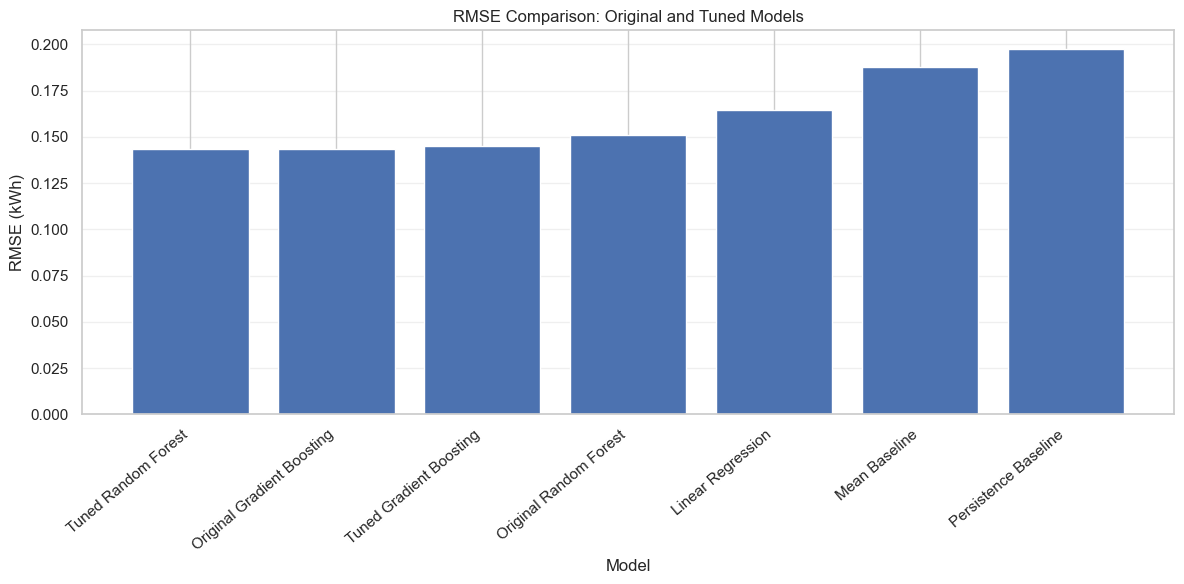


BEST MODEL ON VALIDATION DATA
--------------------------------
Model: Tuned Random Forest
MAE: 0.085524
RMSE: 0.143451


In [53]:
# --------------------------------------------------
# 1. PREDICTIONS FROM TUNED MODELS
# --------------------------------------------------

tuned_rf_predictions = best_rf_model.predict(X_val)
tuned_gb_predictions = best_gb_model.predict(X_val)


# --------------------------------------------------
# 2. COMMON VALIDATION ROWS
# --------------------------------------------------

common_mask = X_val['Previous_Total_Energy_kWh'].notna()

actual = y_val.loc[common_mask]

predictions = {
    'Mean Baseline': np.full(len(actual), y_train.mean()),

    'Persistence Baseline':
        X_val.loc[common_mask, 'Previous_Total_Energy_kWh'].to_numpy(),

    'Linear Regression':
        linear_predictions[common_mask.to_numpy()],

    'Original Random Forest':
        rf_predictions[common_mask.to_numpy()],

    'Original Gradient Boosting':
        gb_predictions[common_mask.to_numpy()],

    'Tuned Random Forest':
        tuned_rf_predictions[common_mask.to_numpy()],

    'Tuned Gradient Boosting':
        tuned_gb_predictions[common_mask.to_numpy()]
}


# --------------------------------------------------
# 3. CALCULATE PERFORMANCE METRICS
# --------------------------------------------------

comparison = []

for model_name, predicted in predictions.items():

    metrics = evaluate_model(actual, predicted)

    comparison.append({
        'Model': model_name,
        'MAE': metrics['MAE'],
        'MSE': metrics['MSE'],
        'RMSE': metrics['RMSE']
    })

final_comparison = pd.DataFrame(comparison)

final_comparison = final_comparison.sort_values(
    by='RMSE'
).reset_index(drop=True)

print("PHASE 4: ORIGINAL VS TUNED MODEL PERFORMANCE")
display(final_comparison.round(6))


# --------------------------------------------------
# 4. VISUAL COMPARISON
# --------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    final_comparison['Model'],
    final_comparison['RMSE']
)

plt.title('RMSE Comparison: Original and Tuned Models')
plt.xlabel('Model')
plt.ylabel('RMSE (kWh)')

plt.xticks(rotation=40, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 5. IDENTIFY THE BEST MODEL
# --------------------------------------------------

best_model_name = final_comparison.iloc[0]['Model']
best_model_rmse = final_comparison.iloc[0]['RMSE']
best_model_mae = final_comparison.iloc[0]['MAE']

print("\nBEST MODEL ON VALIDATION DATA")
print("--------------------------------")
print("Model:", best_model_name)
print("MAE:", round(best_model_mae, 6))
print("RMSE:", round(best_model_rmse, 6))

Phase 5 — Feature importance, error analysis and final test evaluation

Feature importance and prediction error analysis

Calculating feature importance...

FEATURE IMPORTANCE


,Feature,Importance,Std
0,Appliance3_Energy_kWh_lag1,0.063846,0.003457
1,Hour_cos,0.008567,0.001236
2,Hour_sin,0.004964,0.000517
3,Previous_Total_Energy_kWh,0.004195,0.000463
4,Appliance9_Energy_kWh_lag1,0.002397,0.000523
5,Appliance2_Energy_kWh_lag1,0.001478,0.000214
6,Appliance4_Energy_kWh_lag1,0.000236,0.000139
7,Appliance6_Energy_kWh_lag1,0.000121,0.000041
8,Appliance5_Energy_kWh_lag1,0.000076,0.000055
9,Appliance1_Energy_kWh_lag1,0.000071,0.000075


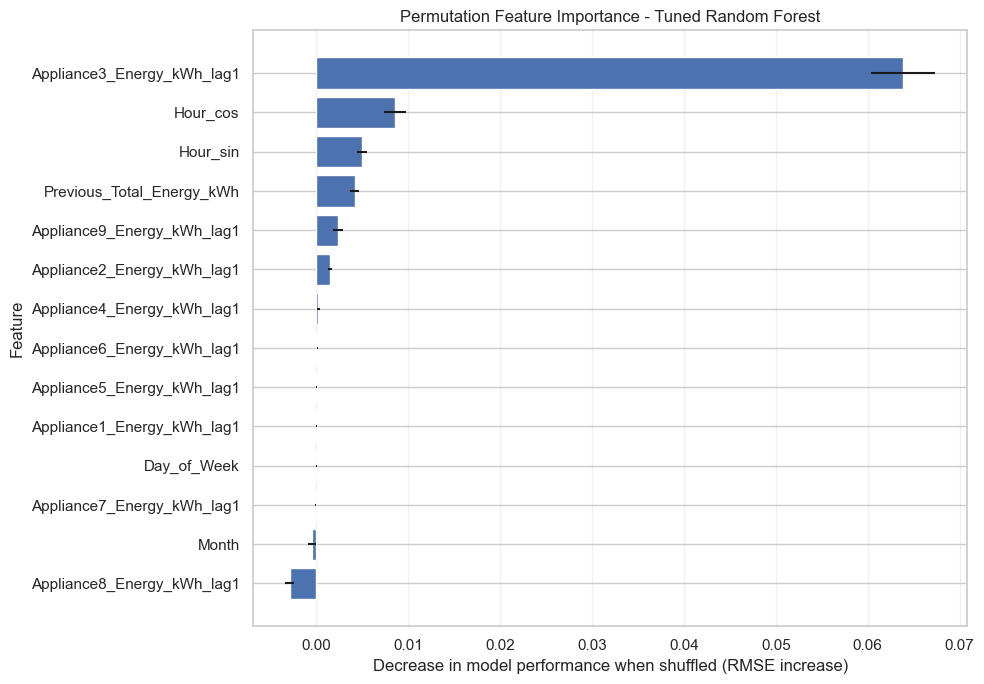


VALIDATION ERROR SUMMARY


,Actual,Predicted,Residual,Absolute_Error
count,1618.000000,1618.000000,1618.000000,1618.000000
mean,0.116883,0.129488,-0.012605,0.086106
std,0.187241,0.133707,0.144560,0.116781
min,0.000666,0.031173,-0.578822,0.000052
25%,0.018147,0.035495,-0.071265,0.017727
50%,0.042361,0.096597,-0.023536,0.045577
75%,0.117085,0.147151,0.006993,0.096768
max,1.344622,0.808474,0.895617,0.895617


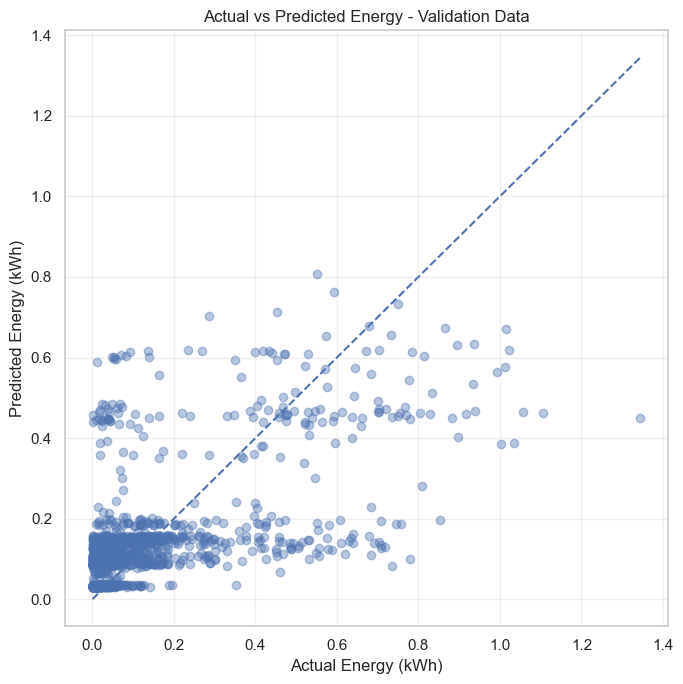

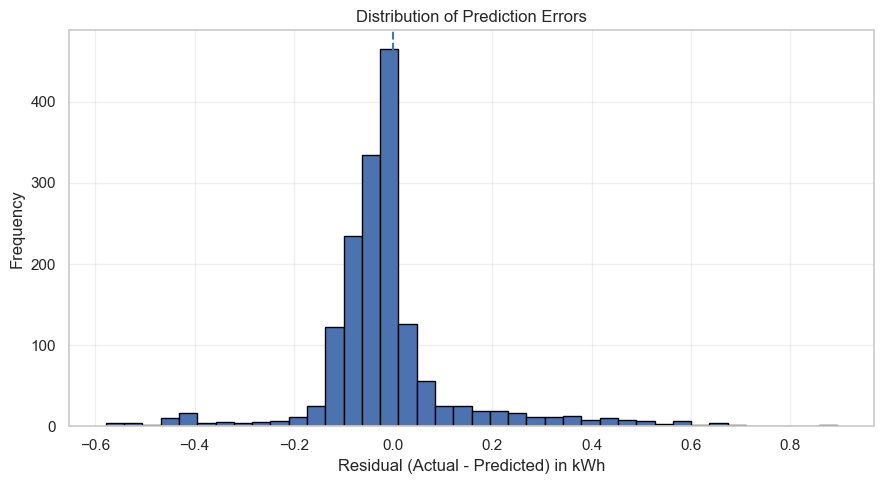

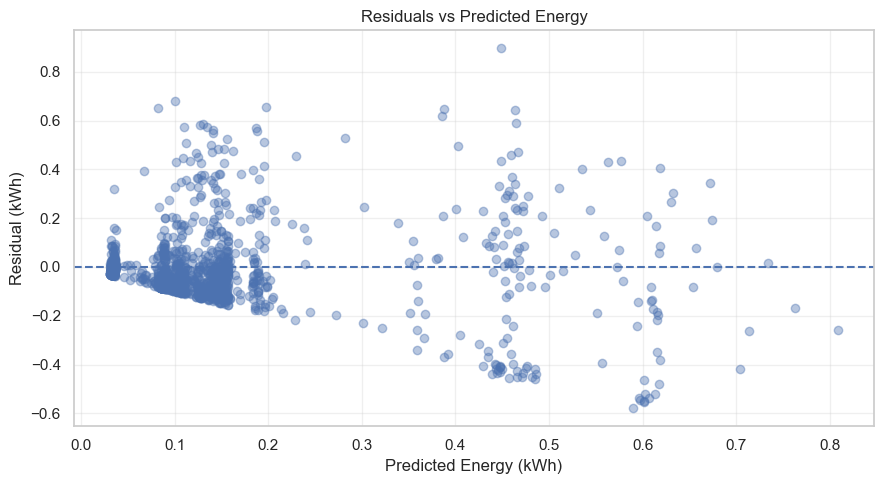


10 LARGEST VALIDATION PREDICTION ERRORS


,Actual,Predicted,Residual,Absolute_Error
Hour,,,,
2015-02-12 21:00:00,1.344622,0.449005,0.895617,0.895617
2015-02-23 12:00:00,0.779996,0.100594,0.679403,0.679403
2015-02-23 17:00:00,0.851949,0.197518,0.654432,0.654432
2015-03-01 11:00:00,0.734215,0.082057,0.652158,0.652158
2014-12-29 19:00:00,1.035720,0.388067,0.647654,0.647654
2015-02-23 19:00:00,1.106617,0.463589,0.643028,0.643028
2014-12-25 19:00:00,1.001869,0.385205,0.616664,0.616664
2015-03-03 19:00:00,1.055637,0.464739,0.590898,0.590898
2015-01-21 20:00:00,0.717596,0.130296,0.587301,0.587301


In [54]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the selected tuned Random Forest model
selected_model = best_rf_model

# --------------------------------------------------
# 1. PERMUTATION FEATURE IMPORTANCE
# --------------------------------------------------

print("Calculating feature importance...")

importance_result = permutation_importance(
    selected_model,
    X_val,
    y_val,
    scoring='neg_root_mean_squared_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\nFEATURE IMPORTANCE")
display(feature_importance.round(6))

# Plot feature importance
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance'],
    xerr=feature_importance['Std']
)

plt.xlabel('Decrease in model performance when shuffled (RMSE increase)')
plt.ylabel('Feature')
plt.title('Permutation Feature Importance - Tuned Random Forest')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. VALIDATION PREDICTIONS AND RESIDUALS
# --------------------------------------------------

validation_predictions = selected_model.predict(X_val)

validation_analysis = pd.DataFrame({
    'Actual': y_val,
    'Predicted': validation_predictions
})

validation_analysis['Residual'] = (
    validation_analysis['Actual'] -
    validation_analysis['Predicted']
)

validation_analysis['Absolute_Error'] = (
    validation_analysis['Residual'].abs()
)

print("\nVALIDATION ERROR SUMMARY")
display(
    validation_analysis[
        ['Actual', 'Predicted', 'Residual', 'Absolute_Error']
    ].describe().round(6)
)


# --------------------------------------------------
# 3. ACTUAL VS PREDICTED
# --------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    validation_analysis['Actual'],
    validation_analysis['Predicted'],
    alpha=0.4
)

minimum = min(
    validation_analysis['Actual'].min(),
    validation_analysis['Predicted'].min()
)

maximum = max(
    validation_analysis['Actual'].max(),
    validation_analysis['Predicted'].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Energy (kWh)')
plt.ylabel('Predicted Energy (kWh)')
plt.title('Actual vs Predicted Energy - Validation Data')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. RESIDUAL DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    validation_analysis['Residual'],
    bins=40,
    edgecolor='black'
)

plt.axvline(0, linestyle='--')

plt.xlabel('Residual (Actual - Predicted) in kWh')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 5. RESIDUALS VS PREDICTED VALUES
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    validation_analysis['Predicted'],
    validation_analysis['Residual'],
    alpha=0.4
)

plt.axhline(0, linestyle='--')

plt.xlabel('Predicted Energy (kWh)')
plt.ylabel('Residual (kWh)')
plt.title('Residuals vs Predicted Energy')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. IDENTIFY LARGEST PREDICTION ERRORS
# --------------------------------------------------

largest_errors = validation_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10)

print("\n10 LARGEST VALIDATION PREDICTION ERRORS")
display(largest_errors.round(6))

Final evaluation using the test dataset

FINAL TEST PERFORMANCE


,Model,MAE,MSE,RMSE
0,Mean Baseline,0.147483,0.057173,0.239110
1,Persistence Baseline,0.137009,0.060992,0.246966
2,Tuned Random Forest,0.104069,0.033664,0.183479



IMPROVEMENT OVER BASELINES
--------------------------------
RMSE improvement over Mean Baseline: 23.27 %
RMSE improvement over Persistence Baseline: 25.71 %


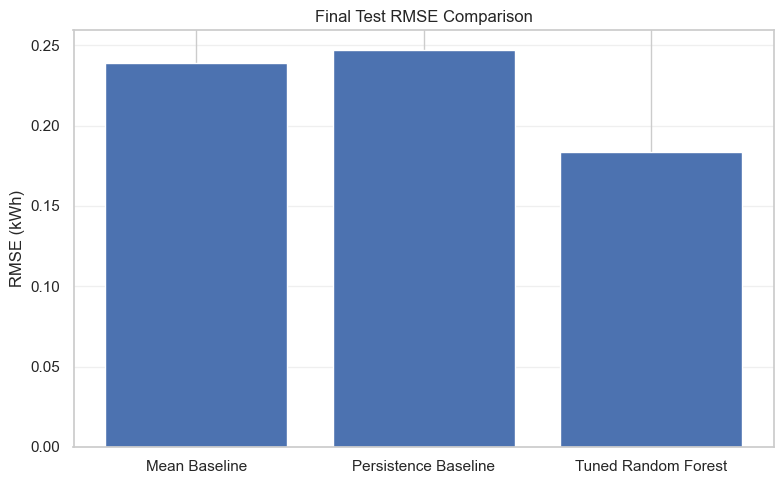


Test predictions saved as Final_Test_Predictions.csv


In [55]:
# --------------------------------------------------
# 1. PREDICT USING THE UNTOUCHED TEST DATA
# --------------------------------------------------

test_predictions = selected_model.predict(X_test)


# --------------------------------------------------
# 2. CREATE A COMMON TEST SAMPLE
# --------------------------------------------------

test_common_mask = X_test[
    'Previous_Total_Energy_kWh'
].notna()

actual_test = y_test.loc[test_common_mask]

predicted_test = test_predictions[test_common_mask.to_numpy()]

mean_test = np.full(
    len(actual_test),
    y_train.mean()
)

persistence_test = X_test.loc[
    test_common_mask,
    'Previous_Total_Energy_kWh'
].to_numpy()


# --------------------------------------------------
# 3. CALCULATE FINAL TEST METRICS
# --------------------------------------------------

test_results = []

test_models = {
    'Mean Baseline': mean_test,
    'Persistence Baseline': persistence_test,
    'Tuned Random Forest': predicted_test
}

for model_name, predictions in test_models.items():

    metrics = evaluate_model(actual_test, predictions)

    test_results.append({
        'Model': model_name,
        'MAE': metrics['MAE'],
        'MSE': metrics['MSE'],
        'RMSE': metrics['RMSE']
    })

test_comparison = pd.DataFrame(test_results)

print("FINAL TEST PERFORMANCE")
display(test_comparison.round(6))


# --------------------------------------------------
# 4. CALCULATE IMPROVEMENT OVER BASELINES
# --------------------------------------------------

rf_test_rmse = test_comparison.loc[
    test_comparison['Model'] == 'Tuned Random Forest',
    'RMSE'
].iloc[0]

mean_test_rmse = test_comparison.loc[
    test_comparison['Model'] == 'Mean Baseline',
    'RMSE'
].iloc[0]

persistence_test_rmse = test_comparison.loc[
    test_comparison['Model'] == 'Persistence Baseline',
    'RMSE'
].iloc[0]

improvement_mean = (
    (mean_test_rmse - rf_test_rmse) / mean_test_rmse
) * 100

improvement_persistence = (
    (persistence_test_rmse - rf_test_rmse)
    / persistence_test_rmse
) * 100

print("\nIMPROVEMENT OVER BASELINES")
print("--------------------------------")
print(
    "RMSE improvement over Mean Baseline:",
    round(improvement_mean, 2), "%"
)

print(
    "RMSE improvement over Persistence Baseline:",
    round(improvement_persistence, 2), "%"
)


# --------------------------------------------------
# 5. PLOT TEST PERFORMANCE
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    test_comparison['Model'],
    test_comparison['RMSE']
)

plt.ylabel('RMSE (kWh)')
plt.title('Final Test RMSE Comparison')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. SAVE TEST PREDICTIONS
# --------------------------------------------------

test_output = pd.DataFrame({
    'Actual_Energy_kWh': y_test,
    'Predicted_Energy_kWh': test_predictions
})

test_output['Residual_kWh'] = (
    test_output['Actual_Energy_kWh'] -
    test_output['Predicted_Energy_kWh']
)

test_output.to_csv(
    'Final_Test_Predictions.csv',
    index=True,
    index_label='Hour'
)

print("\nTest predictions saved as Final_Test_Predictions.csv")

Phase 6 — Final model packaging and integration

Train and save the final deployment model

In [56]:
import pandas as pd
import numpy as np
import joblib
import json
from sklearn.base import clone

# --------------------------------------------------
# 1. COMBINE TRAINING AND VALIDATION DATA
# --------------------------------------------------

X_deployment = pd.concat([X_train, X_val])
y_deployment = pd.concat([y_train, y_val])

print("Training rows:", len(X_deployment))
print("Features:", len(X_deployment.columns))


# --------------------------------------------------
# 2. CREATE FINAL MODEL USING SELECTED PARAMETERS
# --------------------------------------------------

# Clone the tuned Random Forest pipeline.
# This retains its selected hyperparameters but starts
# with fresh, unfitted preprocessing and model objects.

final_deployment_model = clone(best_rf_model)

final_deployment_model.fit(
    X_deployment,
    y_deployment
)

print("\nFinal deployment model trained successfully.")


# --------------------------------------------------
# 3. CREATE MODEL BUNDLE
# --------------------------------------------------

feature_columns = list(X_deployment.columns)

deployment_bundle = {
    'model': final_deployment_model,
    'feature_columns': feature_columns,
    'target_name': 'Total_Energy_kWh',
    'target_unit': 'kWh',
    'model_name': 'Tuned Random Forest',
    'prediction_horizon': 'Next hour'
}

joblib.dump(
    deployment_bundle,
    'smart_home_energy_model.joblib'
)

print("\nModel saved as smart_home_energy_model.joblib")


# --------------------------------------------------
# 4. SAVE MODEL METADATA
# --------------------------------------------------

test_metrics_dict = (
    test_comparison
    .set_index('Model')[['MAE', 'MSE', 'RMSE']]
    .to_dict(orient='index')
)

metadata = {
    'project': 'Smart Home Appliances Manager',
    'model': 'Tuned Random Forest',
    'target': 'Total_Energy_kWh',
    'target_unit': 'kWh',
    'target_definition': (
        'Sum of energy readings from nine monitored appliances'
    ),
    'prediction_horizon': 'One hour ahead',
    'features': feature_columns,
    'training_rows': int(len(X_deployment)),
    'test_performance': {
        model: {
            metric: float(value)
            for metric, value in metrics.items()
        }
        for model, metrics in test_metrics_dict.items()
    },
    'limitations': [
        'Represents nine monitored appliances, not necessarily '
        'the entire household electricity consumption.',
        'Uses previous-hour appliance readings and time features.',
        'Does not directly model hypothetical appliance ON/OFF '
        'decisions made by a game player.',
        'May underestimate unusually high consumption events.'
    ]
}

with open('smart_home_model_metadata.json', 'w') as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved as smart_home_model_metadata.json")


# --------------------------------------------------
# 5. CONFIRM SAVED FILES
# --------------------------------------------------

print("\nFINAL DEPLOYMENT FILES")
print("----------------------")
print("1. smart_home_energy_model.joblib")
print("2. smart_home_model_metadata.json")

Training rows: 9163
Features: 14

Final deployment model trained successfully.

Model saved as smart_home_energy_model.joblib
Metadata saved as smart_home_model_metadata.json

FINAL DEPLOYMENT FILES
----------------------
1. smart_home_energy_model.joblib
2. smart_home_model_metadata.json


Create a prediction function for Person 3

In [57]:
import joblib
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. LOAD THE SAVED MODEL
# --------------------------------------------------

bundle = joblib.load('smart_home_energy_model.joblib')

loaded_model = bundle['model']
feature_columns = bundle['feature_columns']

print("Model loaded successfully.")


# --------------------------------------------------
# 2. DEFINE THE PREDICTION FUNCTION
# --------------------------------------------------

def predict_next_hour(
    appliance_lag_values,
    previous_total_energy,
    target_timestamp
):

    """
    Predict next-hour energy consumption.

    appliance_lag_values:
        Dictionary containing previous-hour readings
        for Appliance 1 to Appliance 9.

    previous_total_energy:
        Previous-hour total monitored-appliance energy.

    target_timestamp:
        Timestamp of the hour being predicted.
    """

    target_timestamp = pd.Timestamp(target_timestamp)

    # Create feature dictionary
    input_data = {}

    # Previous-hour readings for nine appliances
    for i in range(1, 10):

        column_name = f'Appliance{i}_Energy_kWh_lag1'

        input_data[column_name] = appliance_lag_values.get(
            f'Appliance{i}_Energy_kWh',
            np.nan
        )

    # Previous total consumption
    input_data['Previous_Total_Energy_kWh'] = (
        previous_total_energy
    )

    # Time features for the target hour
    hour = target_timestamp.hour

    input_data['Hour_sin'] = np.sin(
        2 * np.pi * hour / 24
    )

    input_data['Hour_cos'] = np.cos(
        2 * np.pi * hour / 24
    )

    input_data['Day_of_Week'] = target_timestamp.dayofweek
    input_data['Month'] = target_timestamp.month

    # Arrange features in the exact training order
    input_df = pd.DataFrame(
        [input_data],
        columns=feature_columns
    )

    # Predict
    prediction = loaded_model.predict(input_df)[0]

    # Energy cannot be negative
    prediction = max(0.0, float(prediction))

    return prediction


# --------------------------------------------------
# 3. TEST THE PREDICTION FUNCTION
# --------------------------------------------------

example_appliance_values = {
    'Appliance1_Energy_kWh': 0.02,
    'Appliance2_Energy_kWh': 0.01,
    'Appliance3_Energy_kWh': 0.15,
    'Appliance4_Energy_kWh': 0.00,
    'Appliance5_Energy_kWh': 0.01,
    'Appliance6_Energy_kWh': 0.02,
    'Appliance7_Energy_kWh': 0.00,
    'Appliance8_Energy_kWh': 0.01,
    'Appliance9_Energy_kWh': 0.03
}

example_previous_total = sum(
    example_appliance_values.values()
)

example_timestamp = '2015-05-29 10:00:00'

predicted_energy = predict_next_hour(
    appliance_lag_values=example_appliance_values,
    previous_total_energy=example_previous_total,
    target_timestamp=example_timestamp
)

print("\nEXAMPLE PREDICTION")
print("-----------------")
print("Target hour:", example_timestamp)
print("Predicted monitored-appliance energy:",
      round(predicted_energy, 4), "kWh")

Model loaded successfully.

EXAMPLE PREDICTION
-----------------
Target hour: 2015-05-29 10:00:00
Predicted monitored-appliance energy: 0.421 kWh
